# Unidad 2. Regresión logística
## Curso: Modelos de Aprendizaje

**Integración de los cuatro trabajos colaborativos**

**Integrantes**
- Ricardo Jovany Gardea González — 22111408
- Jesús Manuel Pereda Chávez — 22111357
- Luis Adán Castro Sánchez — 22111352
- Jesús Isaac Antonio Altamirano — 22111389

---

### Objetivo
Explorar el conjunto de datos de diagnóstico de cáncer de mama, identificar variables altamente correlacionadas y construir dos clasificadores de regresión logística: un modelo base y otro con transformación de variables y escalamiento.

> **Nota:** El modelo es un ejercicio académico de clasificación y no debe utilizarse para realizar diagnósticos médicos.

## 1. Importación de librerías

Se reúnen las librerías utilizadas en los cuatro Colab, evitando importaciones duplicadas. Algunas se conservan porque forman parte del material de la unidad, aunque no todas se requieren en los dos modelos finales.

In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    MinMaxScaler, OneHotEncoder, StandardScaler,
    OrdinalEncoder, FunctionTransformer, PolynomialFeatures
)
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    confusion_matrix, precision_score, recall_score, accuracy_score,
    classification_report
)
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)

### Función de las principales librerías

| Librería | Uso |
|---|---|
| `pandas` | Leer y manipular datos tabulares mediante DataFrames. |
| `numpy` | Operaciones matemáticas y arreglos numéricos. |
| `matplotlib` y `seaborn` | Crear gráficas y visualizaciones estadísticas. |
| `SimpleImputer` | Sustituir valores faltantes. |
| `MinMaxScaler` / `StandardScaler` | Escalar variables numéricas. |
| `OneHotEncoder` / `OrdinalEncoder` | Codificar variables categóricas. |
| `FunctionTransformer` | Incorporar funciones como `np.sqrt` a un pipeline. |
| `ColumnTransformer` | Aplicar transformaciones a columnas específicas. |
| `make_pipeline` | Encadenar preprocesamiento y modelo. |
| `LogisticRegression` | Clasificar observaciones en categorías. |
| `confusion_matrix`, `precision_score`, `recall_score`, `accuracy_score` | Evaluar el clasificador. |
| `PCA` | Reducir dimensionalidad mediante componentes principales. |
| `PolynomialFeatures` | Generar características polinomiales e interacciones. |
| `LinearRegression` | Regresión para variables continuas; se conserva como referencia de la unidad. |

## 2. Carga y preparación inicial de los datos

Ejecuta la celda y selecciona el archivo **actividad RegresionLogistica.csv**. También puedes modificar `RUTA_CSV` si el archivo está en Google Drive.

In [24]:
from google.colab import drive
import pandas as pd

drive.mount('/content/drive')

file_path = "/content/drive/MyDrive/IA/ARL.csv"

data_df = pd.read_csv(file_path)

data_df = data_df.loc[:, ~data_df.columns.astype(str).str.contains(r"^Unnamed")]

if "id" in data_df.columns:
    data_df.set_index("id", inplace=True)

print("Dimensiones:", data_df.shape)
display(data_df.head())

Mounted at /content/drive
Dimensiones: (569, 31)


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## Parte 1. Análisis exploratorio de datos (EDA)

### 1a. Estadísticas descriptivas
Se revisan las estadísticas de las variables numéricas y de la variable categórica.

In [7]:
display(data_df.describe().T)
display(data_df.describe(include="object").T)

,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
texture_mean,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
perimeter_mean,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
area_mean,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
smoothness_mean,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
compactness_mean,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
concavity_mean,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
concave points_mean,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
symmetry_mean,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
fractal_dimension_mean,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


,count,unique,top,freq
diagnosis,569,2,B,357


### 1b. Valores únicos y frecuencia de categorías

In [8]:
print("Cantidad de valores únicos por columna:")
display(data_df.nunique().sort_values(ascending=False).to_frame("valores_unicos"))

num_cols_initial = data_df.select_dtypes(include=np.number).columns.tolist()
cat_cols_initial = data_df.select_dtypes(exclude=np.number).columns.tolist()

print("Columnas numéricas:", num_cols_initial)
print("Columnas categóricas:", cat_cols_initial)

for col in cat_cols_initial:
    print(f"\nFrecuencias de {col}:")
    display(data_df[col].value_counts(dropna=False).to_frame("frecuencia"))
    display((data_df[col].value_counts(normalize=True, dropna=False) * 100).round(2).to_frame("porcentaje"))

Cantidad de valores únicos por columna:


,valores_unicos
smoothness_se,547
fractal_dimension_se,545
area_worst,544
concave points_mean,542
compactness_se,541
radius_se,540
area_mean,539
concavity_worst,539
compactness_mean,537
concavity_mean,537


Columnas numéricas: ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']
Columnas categóricas: ['diagnosis']

Frecuencias de diagnosis:


,frecuencia
diagnosis,
B,357
M,212


,porcentaje
diagnosis,
B,62.74
M,37.26


### 1c. Búsqueda de valores faltantes

In [9]:
faltantes = pd.DataFrame({
    "cantidad": data_df.isna().sum(),
    "porcentaje": (data_df.isna().mean() * 100).round(2)
})
display(faltantes)
print("Total de valores faltantes:", int(data_df.isna().sum().sum()))

,cantidad,porcentaje
diagnosis,0,0.0
radius_mean,0,0.0
texture_mean,0,0.0
perimeter_mean,0,0.0
area_mean,0,0.0
smoothness_mean,0,0.0
compactness_mean,0,0.0
concavity_mean,0,0.0
concave points_mean,0,0.0
symmetry_mean,0,0.0


Total de valores faltantes: 0


**Interpretación:** Si el total de valores faltantes es cero, no es necesario aplicar imputación para este conjunto de datos. Si aparecen faltantes, deben tratarse antes del entrenamiento.

### 1d. Frecuencia de diagnósticos benignos y malignos

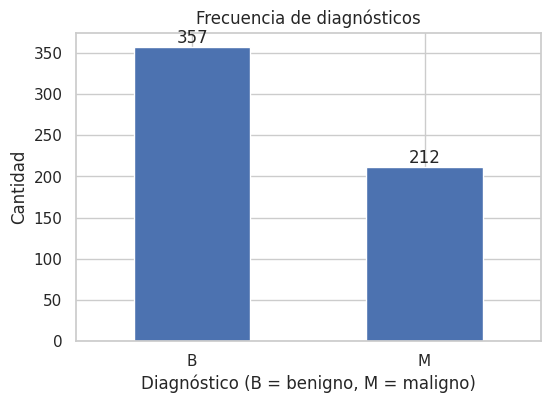

,porcentaje
diagnosis,
B,62.74
M,37.26


In [10]:
plt.figure(figsize=(6, 4))
conteos = data_df["diagnosis"].value_counts().reindex(["B", "M"], fill_value=0)
ax = conteos.plot(kind="bar", figsize=(6, 4), rot=0)
ax.bar_label(ax.containers[0])
plt.title("Frecuencia de diagnósticos")
plt.xlabel("Diagnóstico (B = benigno, M = maligno)")
plt.ylabel("Cantidad")
plt.show()

display((data_df["diagnosis"].value_counts(normalize=True) * 100).round(2).to_frame("porcentaje"))

### 2. Identificación de multicolinealidad

Las columnas terminadas en `_mean`, `_se` y `_worst` describen características relacionadas. Se utiliza una matriz de correlación para detectar pares de variables con correlaciones altas.

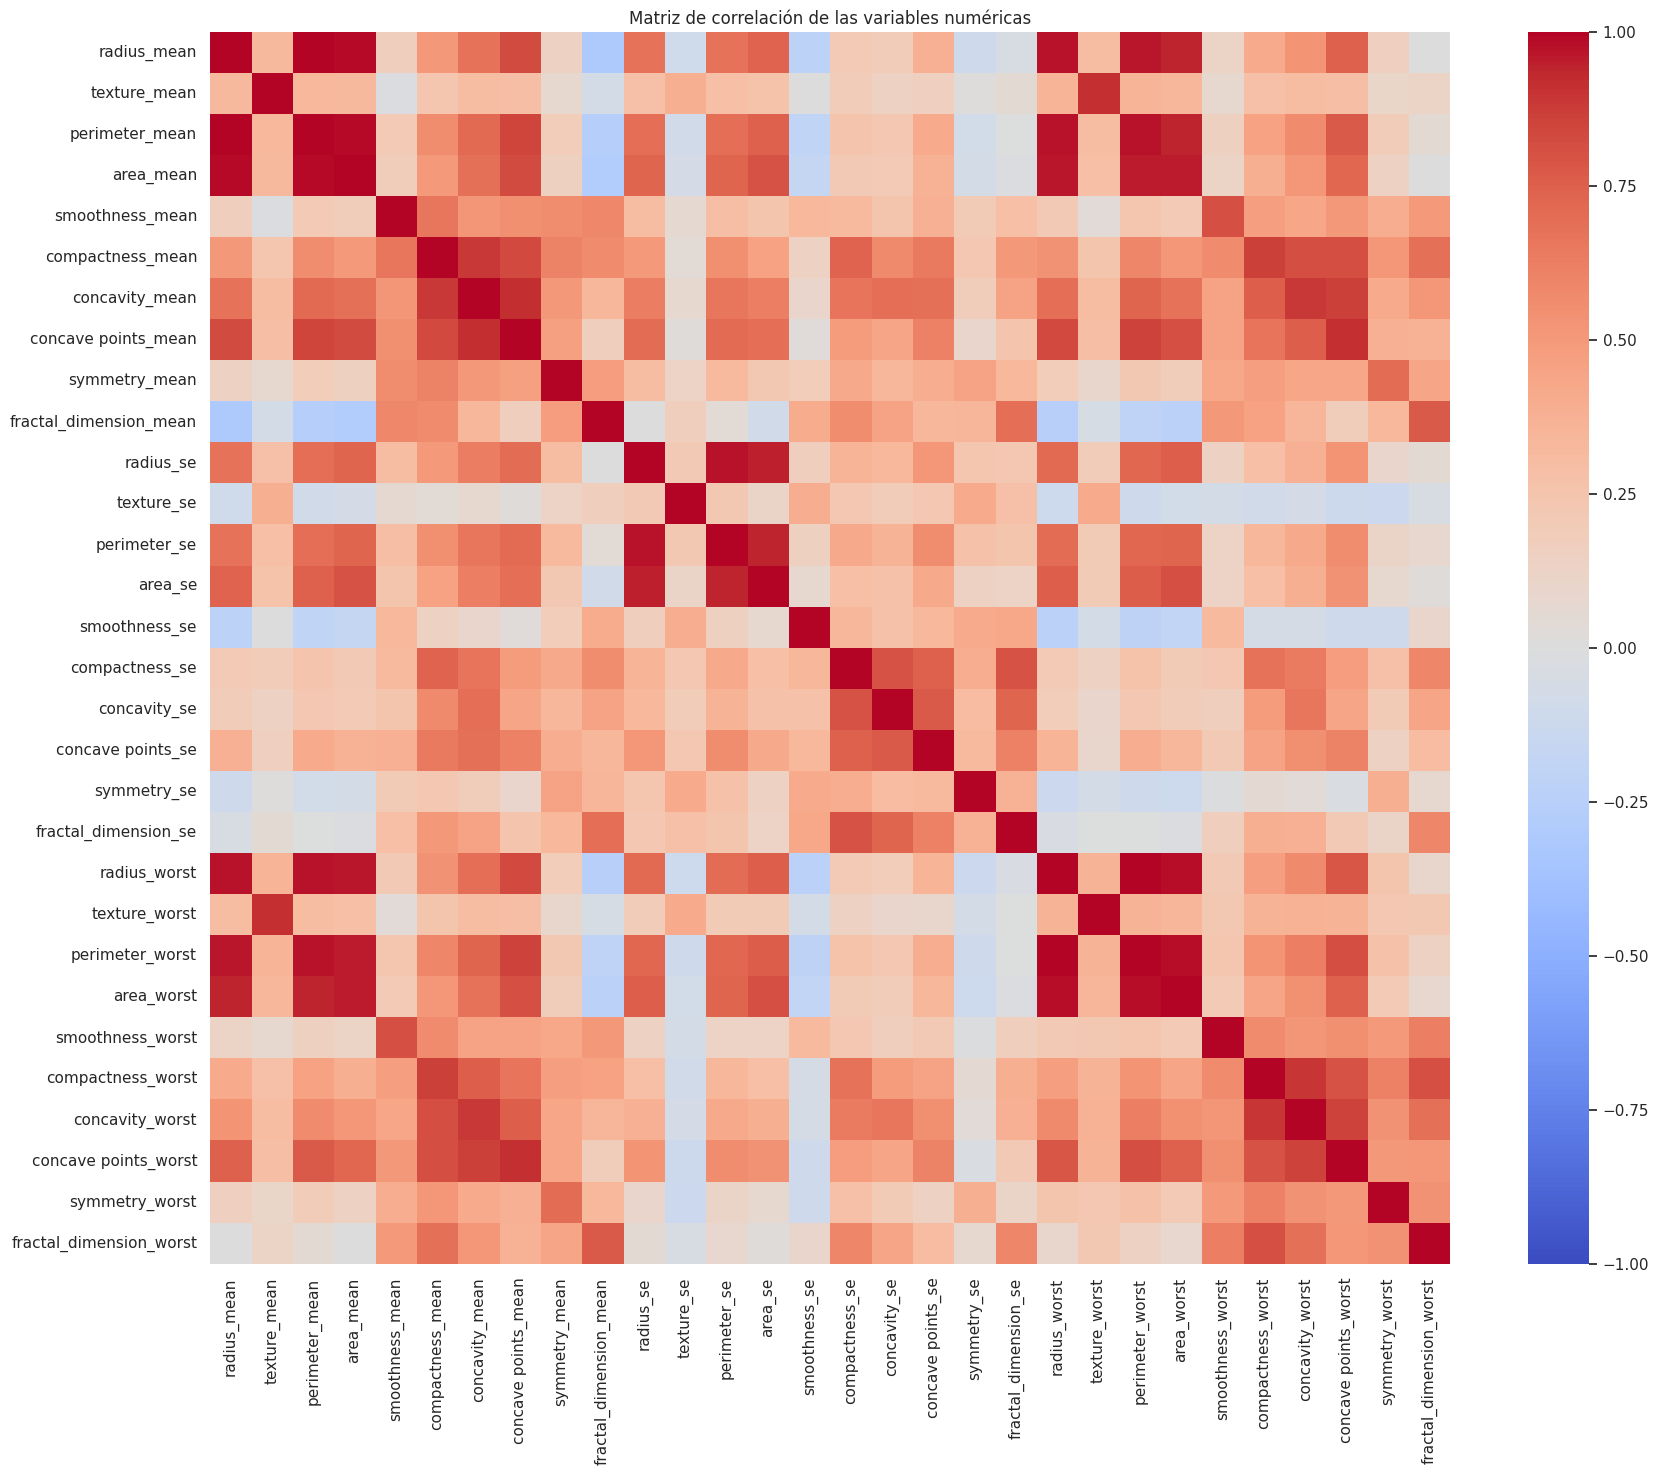

In [11]:
numeric_df = data_df.select_dtypes(include=np.number)
correlation = numeric_df.corr(method="pearson")

plt.figure(figsize=(20, 16))
sns.heatmap(correlation, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlación de las variables numéricas")
plt.show()

**Interpretación:** Los bloques de correlaciones altas indican que algunas variables aportan información similar. La multicolinealidad puede dificultar la interpretación de los coeficientes, por lo que se selecciona un conjunto reducido de características.

## Parte 2. Selección de variables

### 3a. Eliminar las columnas `_worst`

Se crea una copia del DataFrame y se eliminan todas las variables cuyo nombre termina en `_worst`.

In [12]:
new_data_df = data_df.copy()
columnas_worst = [col for col in new_data_df.columns if col.endswith("_worst")]
new_data_df = new_data_df.drop(columns=columnas_worst)

print("Columnas eliminadas:", columnas_worst)
print("Dimensiones después de eliminar _worst:", new_data_df.shape)

Columnas eliminadas: ['radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']
Dimensiones después de eliminar _worst: (569, 21)


### 3b y 3c. Diagramas de dispersión y nueva matriz de correlación

Se visualizan algunas variables representativas y se vuelve a revisar la correlación después de eliminar `_worst`.

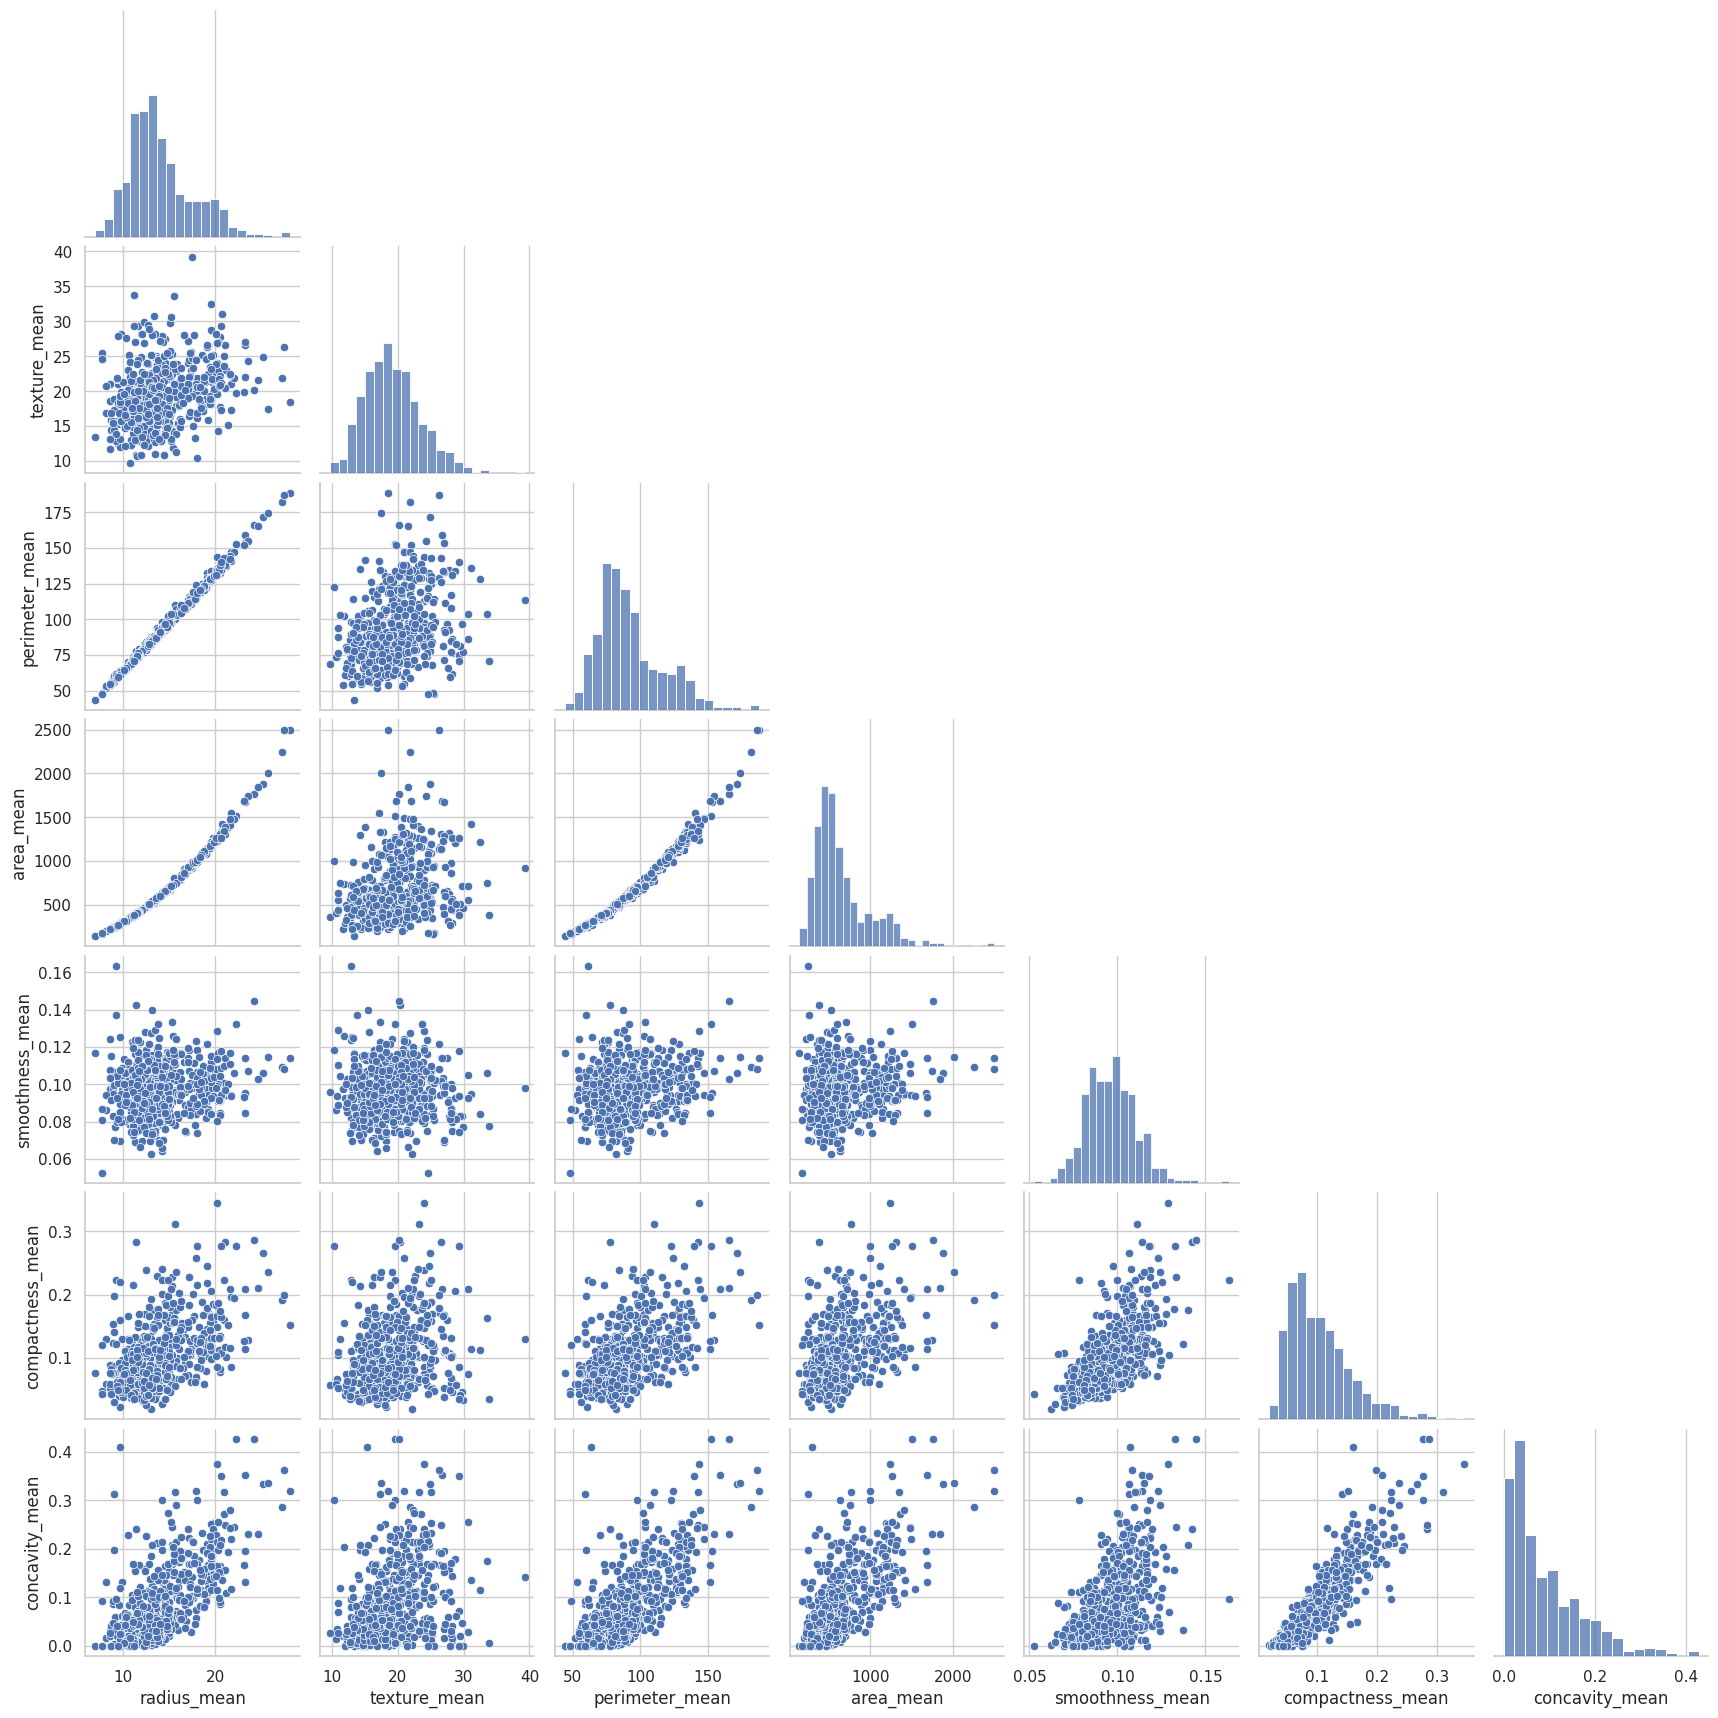

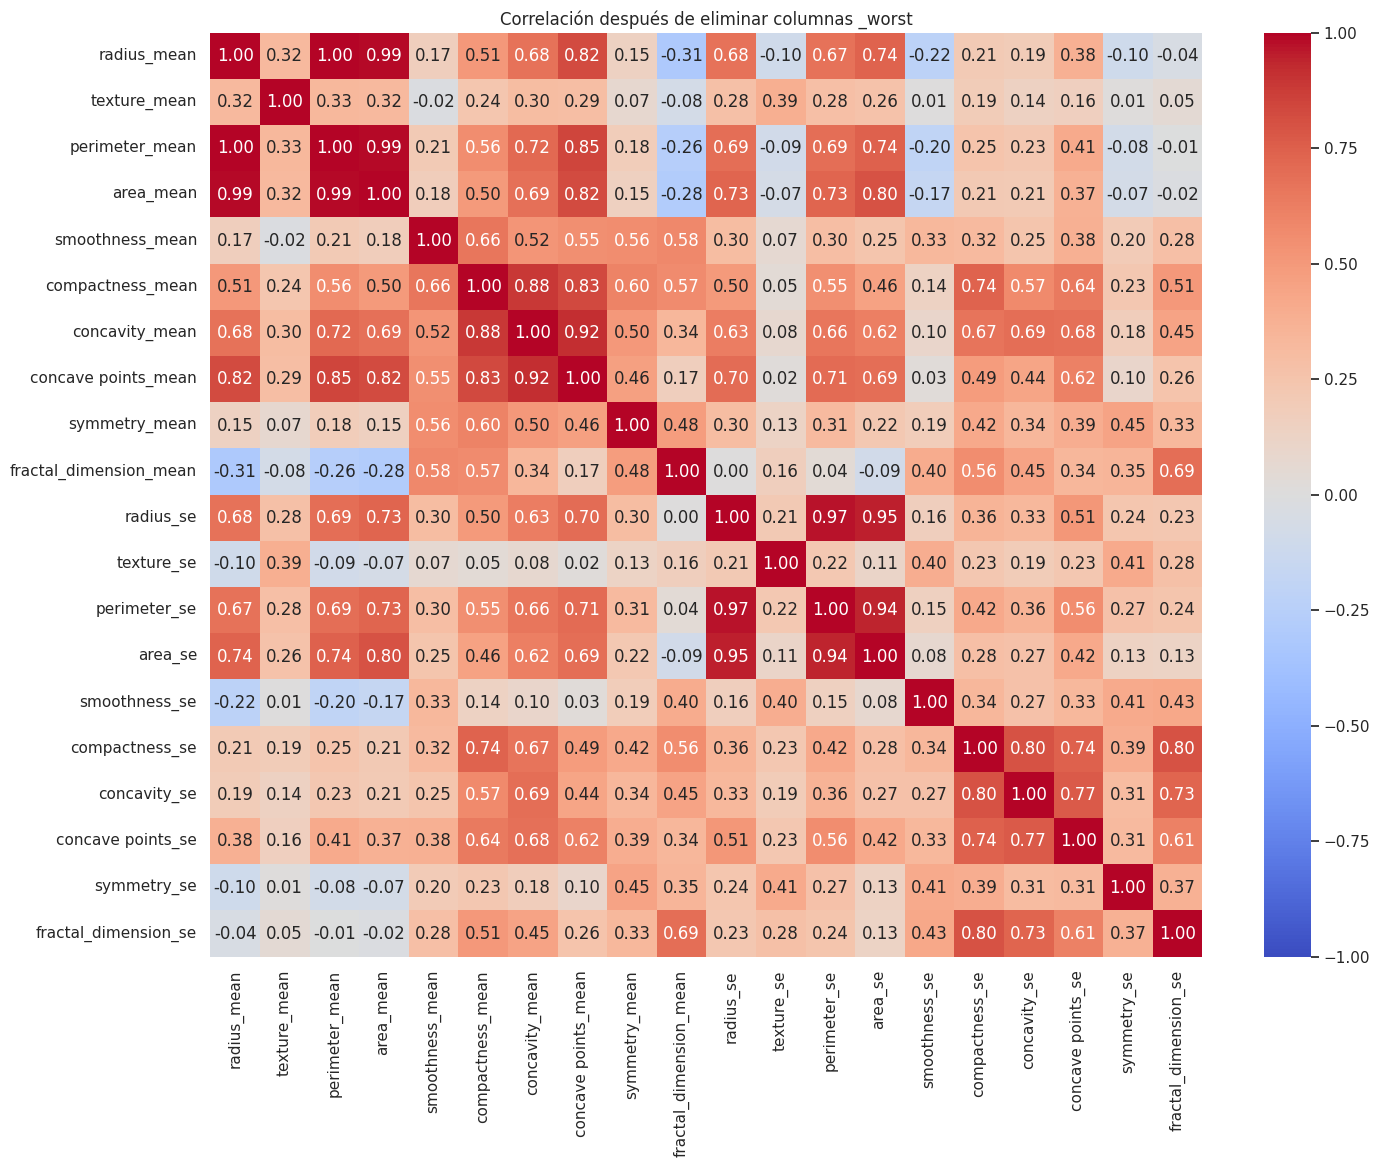

In [13]:
variables_pairplot = [
    "radius_mean", "texture_mean", "perimeter_mean", "area_mean",
    "smoothness_mean", "compactness_mean", "concavity_mean"
]
sns.pairplot(new_data_df[variables_pairplot], corner=True)
plt.show()

numeric_df2 = new_data_df.select_dtypes(include=np.number)
plt.figure(figsize=(16, 12))
sns.heatmap(numeric_df2.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación después de eliminar columnas _worst")
plt.show()

### 3d. Eliminar variables redundantes

De acuerdo con la revisión de los cuatro trabajos, se conserva una variable representativa de cada grupo: `radius_mean` y `compactness_mean`. También se eliminan sus variables relacionadas en `_mean` y `_se` indicadas en la actividad.

In [14]:
columnas_redundantes = [
    "perimeter_mean", "area_mean", "concavity_mean", "concave points_mean",
    "perimeter_se", "area_se", "concavity_se", "concave points_se"
]
new_data_df = new_data_df.drop(columns=columnas_redundantes, errors="ignore")

num_cols = new_data_df.select_dtypes(include=np.number).columns.tolist()
print("Variables numéricas restantes:", len(num_cols))
print("Columnas:", new_data_df.columns.tolist())
display(new_data_df.head())

Variables numéricas restantes: 12
Columnas: ['diagnosis', 'radius_mean', 'texture_mean', 'smoothness_mean', 'compactness_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'smoothness_se', 'compactness_se', 'symmetry_se', 'fractal_dimension_se']


,diagnosis,radius_mean,texture_mean,smoothness_mean,compactness_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,smoothness_se,compactness_se,symmetry_se,fractal_dimension_se
id,,,,,,,,,,,,,
842302,M,17.99,10.38,0.11840,0.27760,0.2419,0.07871,1.0950,0.9053,0.006399,0.04904,0.03003,0.006193
842517,M,20.57,17.77,0.08474,0.07864,0.1812,0.05667,0.5435,0.7339,0.005225,0.01308,0.01389,0.003532
84300903,M,19.69,21.25,0.10960,0.15990,0.2069,0.05999,0.7456,0.7869,0.006150,0.04006,0.02250,0.004571
84348301,M,11.42,20.38,0.14250,0.28390,0.2597,0.09744,0.4956,1.1560,0.009110,0.07458,0.05963,0.009208
84358402,M,20.29,14.34,0.10030,0.13280,0.1809,0.05883,0.7572,0.7813,0.011490,0.02461,0.01756,0.005115


### 4a. Histogramas y detección de sesgo positivo

Se consideran con sesgo positivo marcado las variables cuyo coeficiente `skew()` es mayor que 1.

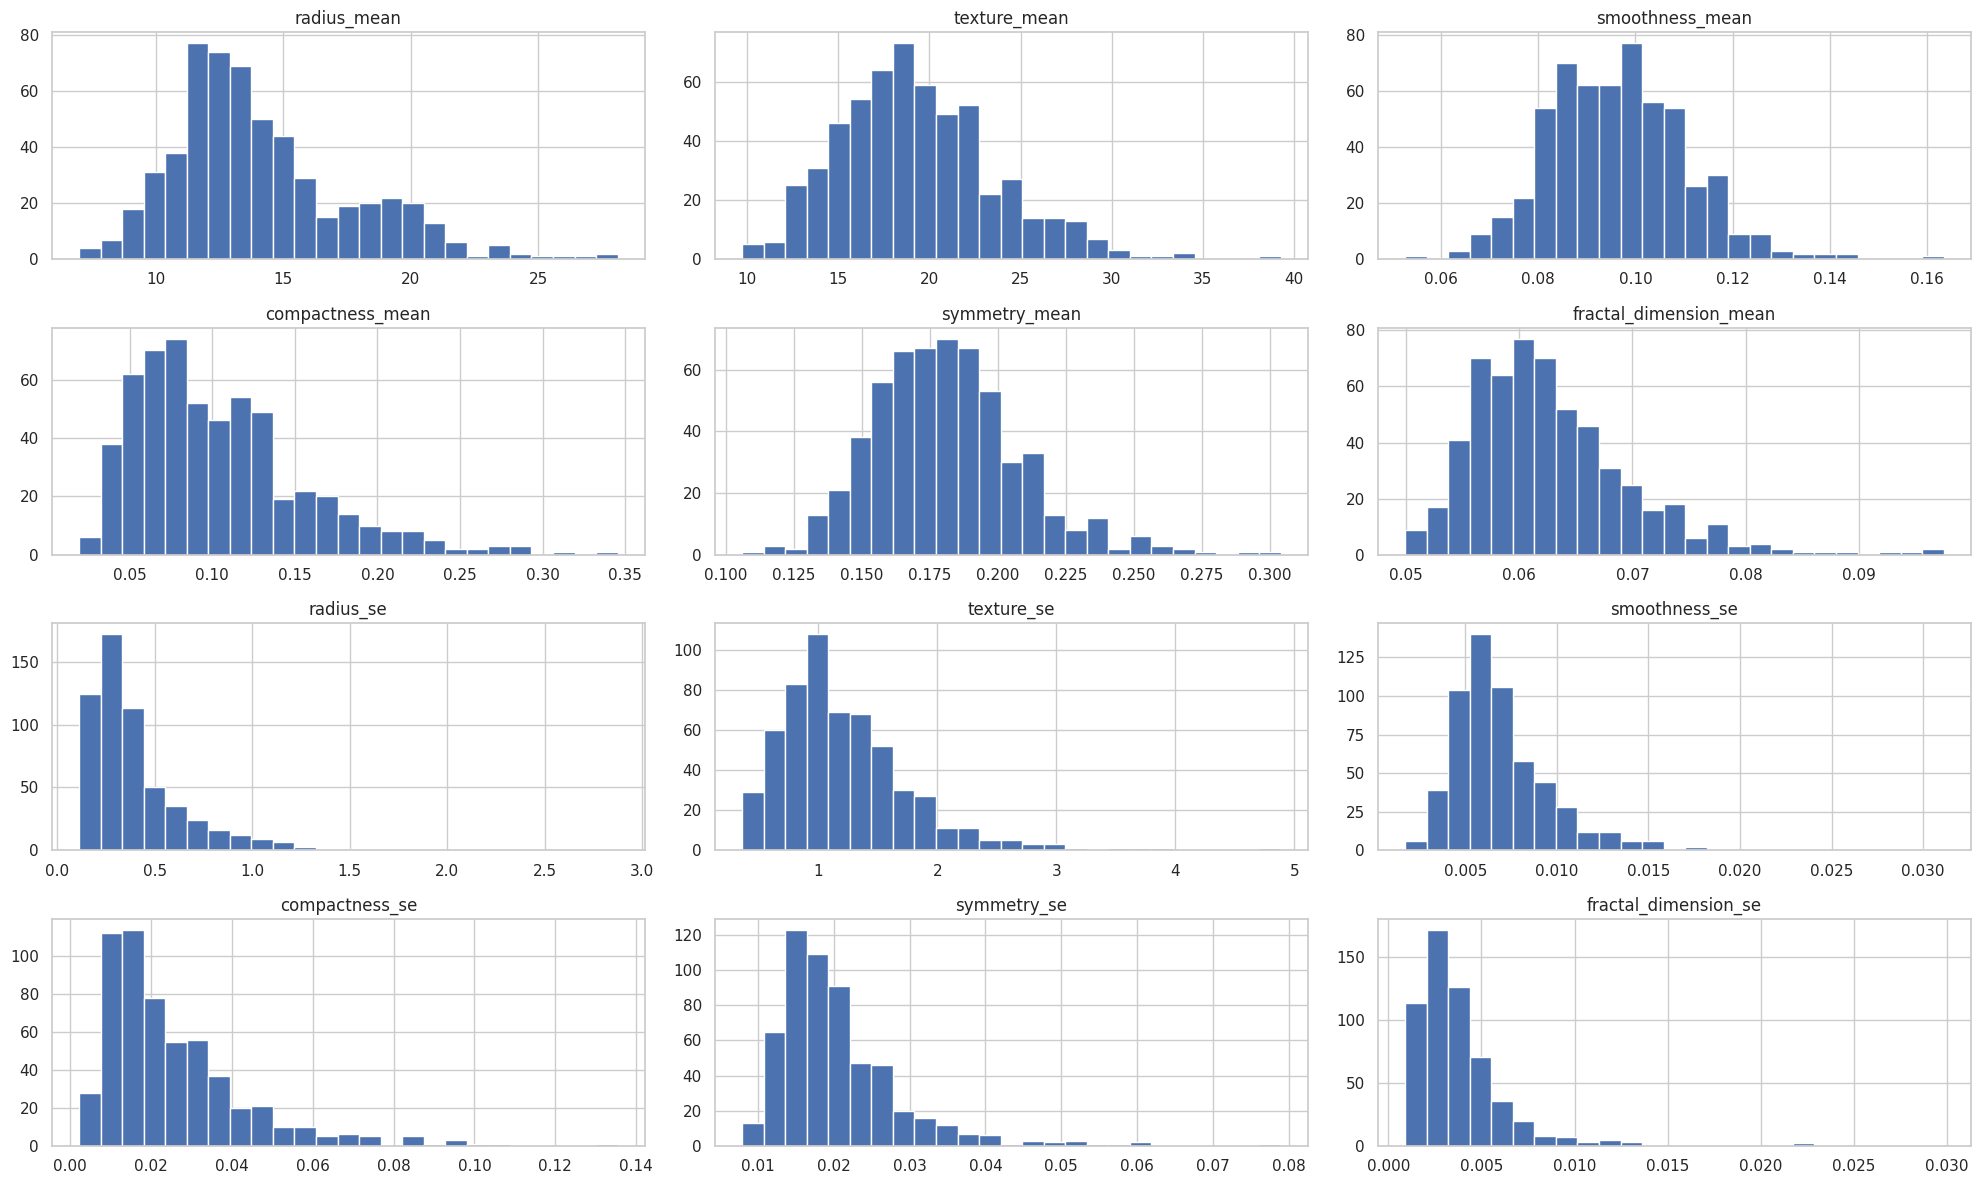

,skew
fractal_dimension_se,3.923969
radius_se,3.088612
smoothness_se,2.314450
symmetry_se,2.195133
compactness_se,1.902221
texture_se,1.646444
fractal_dimension_mean,1.304489
compactness_mean,1.190123
radius_mean,0.942380
symmetry_mean,0.725609


Variables con sesgo positivo (skew > 1): ['compactness_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'smoothness_se', 'compactness_se', 'symmetry_se', 'fractal_dimension_se']


In [15]:
skew_values = new_data_df[num_cols].skew()
skew_cols = skew_values[skew_values > 1].index.tolist()

fig, axes = plt.subplots(4, 3, figsize=(20, 12))
axes = axes.ravel()
for col, ax in zip(num_cols, axes):
    ax.hist(new_data_df[col], bins=25)
    ax.set_title(col)
for ax in axes[len(num_cols):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

display(skew_values.sort_values(ascending=False).to_frame("skew"))
print("Variables con sesgo positivo (skew > 1):", skew_cols)

### 4b. Box plots y detección de variables fuera del intervalo [0, 1]

Se identifican las variables cuyo mínimo es menor que 0 o cuyo máximo es mayor que 1.

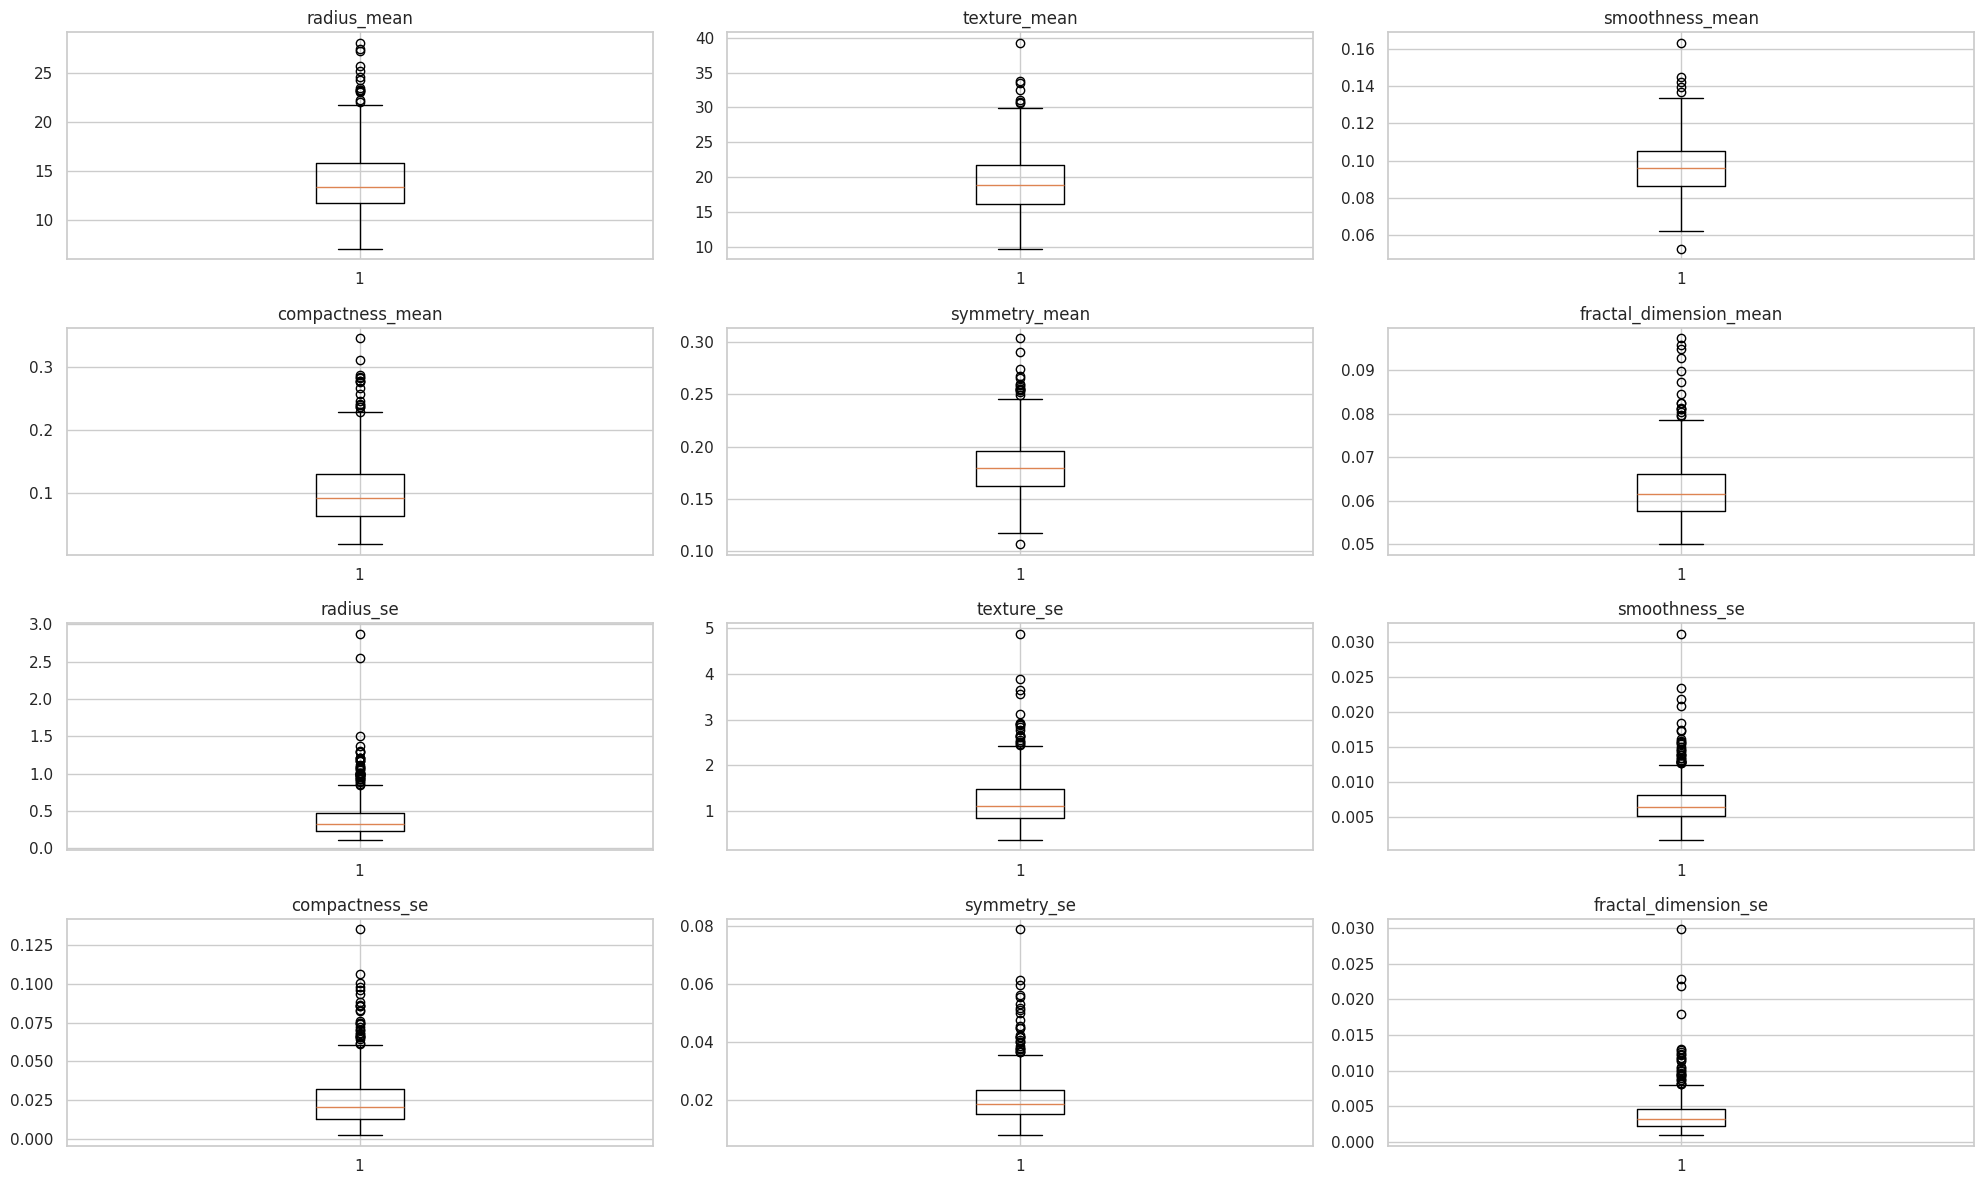

,min,max
radius_mean,6.981000,28.11000
texture_mean,9.710000,39.28000
smoothness_mean,0.052630,0.16340
compactness_mean,0.019380,0.34540
symmetry_mean,0.106000,0.30400
fractal_dimension_mean,0.049960,0.09744
radius_se,0.111500,2.87300
texture_se,0.360200,4.88500
smoothness_se,0.001713,0.03113
compactness_se,0.002252,0.13540


Variables fuera del intervalo [0, 1]: ['radius_mean', 'texture_mean', 'radius_se', 'texture_se']
Variables presentes en ambas listas: ['radius_se', 'texture_se']


In [16]:
rangos = new_data_df[num_cols].agg(["min", "max"]).T
scale_cols = rangos[(rangos["min"] < 0) | (rangos["max"] > 1)].index.tolist()

fig, axes = plt.subplots(4, 3, figsize=(20, 12))
axes = axes.ravel()
for col, ax in zip(num_cols, axes):
    ax.boxplot(new_data_df[col].dropna())
    ax.set_title(col)
for ax in axes[len(num_cols):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

display(rangos)
print("Variables fuera del intervalo [0, 1]:", scale_cols)
print("Variables presentes en ambas listas:", sorted(set(skew_cols) & set(scale_cols)))

## Parte 3. Construcción y evaluación de los modelos

### 5a. Separar predictores y variable objetivo

Se vuelve a partir del conjunto original para entrenar y probar los modelos con la misma partición. Se utiliza una división 80:20 y `random_state=1` para reproducibilidad.

In [17]:
X = data_df.drop(columns=["diagnosis"]).copy()
y = data_df["diagnosis"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=1
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)

X_train: (455, 30) | X_test: (114, 30)
y_train: (455,) | y_test: (114,)


### 5b. Transformador para eliminar las 18 variables correlacionadas

Se eliminan las diez columnas `_worst` y las ocho variables redundantes seleccionadas en los apartados anteriores. `remainder="passthrough"` conserva las demás columnas.

In [18]:
columnas_a_eliminar = columnas_worst + columnas_redundantes
# Mantener solo nombres que realmente existan en X_train.
columnas_a_eliminar = [c for c in columnas_a_eliminar if c in X_train.columns]

preprocessing = ColumnTransformer(
    transformers=[
        ("eliminar_correlacionadas", "drop", columnas_a_eliminar)
    ],
    remainder="passthrough"
)

print("Columnas eliminadas:", len(columnas_a_eliminar))
print(columnas_a_eliminar)

Columnas eliminadas: 18
['radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'perimeter_mean', 'area_mean', 'concavity_mean', 'concave points_mean', 'perimeter_se', 'area_se', 'concavity_se', 'concave points_se']


### 5c. Modelo 1: regresión logística baseline

Se entrena el pipeline y se evalúa mediante matriz de confusión, recall, precisión y accuracy. La clase positiva se define como `M` (maligno).

In [19]:
logr_model = make_pipeline(
    preprocessing,
    LogisticRegression(max_iter=2000)
)

logr_model.fit(X_train, y_train)
predictions = logr_model.predict(X_test)

cm1 = confusion_matrix(y_test, predictions, labels=["B", "M"])
tn, fp, fn, tp = cm1.ravel()

print("Matriz de confusión (filas = real, columnas = predicción; orden B, M):")
print(cm1)
print("Recall (M):", recall_score(y_test, predictions, pos_label="M"))
print("Precision (M):", precision_score(y_test, predictions, pos_label="M"))
print("Accuracy:", accuracy_score(y_test, predictions))
print("\nReporte de clasificación:")
print(classification_report(y_test, predictions, labels=["B", "M"]))

Matriz de confusión (filas = real, columnas = predicción; orden B, M):
[[68  4]
 [10 32]]
Recall (M): 0.7619047619047619
Precision (M): 0.8888888888888888
Accuracy: 0.8771929824561403

Reporte de clasificación:
              precision    recall  f1-score   support

           B       0.87      0.94      0.91        72
           M       0.89      0.76      0.82        42

    accuracy                           0.88       114
   macro avg       0.88      0.85      0.86       114
weighted avg       0.88      0.88      0.87       114



In [ ]:
plt.figure(figsize=(5, 4))
sns.heatmap(
    cm1, annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=["B predicho", "M predicho"],
    yticklabels=["B real", "M real"]
)
plt.title("Matriz de confusión - Modelo 1")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.show()

print(f"Verdaderos negativos (VN): {tn} | Falsos positivos (FP): {fp}")
print(f"Falsos negativos (FN): {fn} | Verdaderos positivos (VP): {tp}")

### 6a. Transformador con raíz cuadrada y escalamiento MinMax

Además de eliminar las variables correlacionadas, se aplica raíz cuadrada a las variables con sesgo positivo y MinMaxScaler a las variables fuera del intervalo [0, 1].

Para evitar transformar dos veces una misma columna, las variables que aparecen en ambas listas se escalan con MinMax y se excluyen del grupo de raíz cuadrada.

In [20]:
# Las transformaciones se calculan a partir del conjunto reducido utilizado en el EDA.
# Solo se usan columnas existentes en X_train y que no fueron eliminadas.
columnas_restantes = [c for c in X_train.columns if c not in columnas_a_eliminar]

skew_cols_model = [c for c in skew_cols if c in columnas_restantes]
scale_cols_model = [c for c in scale_cols if c in columnas_restantes]

# Evita duplicar una variable si pertenece a ambas listas.
sqrt_only_cols = [c for c in skew_cols_model if c not in scale_cols_model]

preprocessing2 = ColumnTransformer(
    transformers=[
        ("eliminar_correlacionadas", "drop", columnas_a_eliminar),
        ("raiz_cuadrada", FunctionTransformer(np.sqrt, feature_names_out="one-to-one"), sqrt_only_cols),
        ("escalamiento", MinMaxScaler(), scale_cols_model)
    ],
    remainder="passthrough"
)

print("Columnas con raíz cuadrada:", sqrt_only_cols)
print("Columnas escaladas:", scale_cols_model)

Columnas con raíz cuadrada: ['compactness_mean', 'fractal_dimension_mean', 'smoothness_se', 'compactness_se', 'symmetry_se', 'fractal_dimension_se']
Columnas escaladas: ['radius_mean', 'texture_mean', 'radius_se', 'texture_se']


### 6b. Modelo 2: regresión logística con transformación y escalamiento

Se entrena y evalúa el segundo pipeline usando exactamente los mismos conjuntos de entrenamiento y prueba.

In [21]:
logr_model2 = make_pipeline(
    preprocessing2,
    LogisticRegression(max_iter=2000)
)

logr_model2.fit(X_train, y_train)
predictions2 = logr_model2.predict(X_test)

cm2 = confusion_matrix(y_test, predictions2, labels=["B", "M"])
tn2, fp2, fn2, tp2 = cm2.ravel()

print("Matriz de confusión 2 (orden B, M):")
print(cm2)
print("Recall (M):", recall_score(y_test, predictions2, pos_label="M"))
print("Precision (M):", precision_score(y_test, predictions2, pos_label="M"))
print("Accuracy:", accuracy_score(y_test, predictions2))
print("\nReporte de clasificación:")
print(classification_report(y_test, predictions2, labels=["B", "M"]))

Matriz de confusión 2 (orden B, M):
[[72  0]
 [11 31]]
Recall (M): 0.7380952380952381
Precision (M): 1.0
Accuracy: 0.9035087719298246

Reporte de clasificación:
              precision    recall  f1-score   support

           B       0.87      1.00      0.93        72
           M       1.00      0.74      0.85        42

    accuracy                           0.90       114
   macro avg       0.93      0.87      0.89       114
weighted avg       0.92      0.90      0.90       114



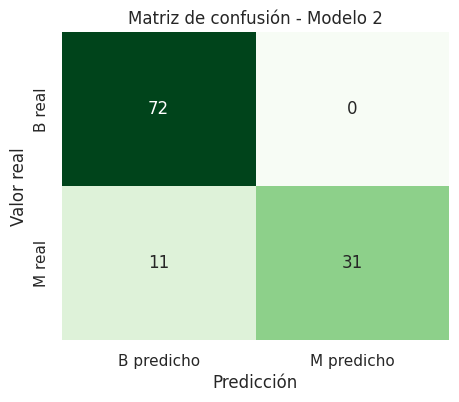

Verdaderos negativos (VN): 72 | Falsos positivos (FP): 0
Falsos negativos (FN): 11 | Verdaderos positivos (VP): 31


In [22]:
plt.figure(figsize=(5, 4))
sns.heatmap(
    cm2, annot=True, fmt="d", cmap="Greens", cbar=False,
    xticklabels=["B predicho", "M predicho"],
    yticklabels=["B real", "M real"]
)
plt.title("Matriz de confusión - Modelo 2")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.show()

print(f"Verdaderos negativos (VN): {tn2} | Falsos positivos (FP): {fp2}")
print(f"Falsos negativos (FN): {fn2} | Verdaderos positivos (VP): {tp2}")

### 7. Comparación de los dos modelos

In [23]:
comparacion = pd.DataFrame({
    "Modelo": ["Modelo 1 (baseline)", "Modelo 2 (raíz + MinMax)"],
    "VN": [tn, tn2],
    "FP": [fp, fp2],
    "FN": [fn, fn2],
    "VP": [tp, tp2],
    "Recall (M)": [
        recall_score(y_test, predictions, pos_label="M"),
        recall_score(y_test, predictions2, pos_label="M")
    ],
    "Precision (M)": [
        precision_score(y_test, predictions, pos_label="M"),
        precision_score(y_test, predictions2, pos_label="M")
    ],
    "Accuracy": [
        accuracy_score(y_test, predictions),
        accuracy_score(y_test, predictions2)
    ]
}).set_index("Modelo")

display(comparacion.round(4))

,VN,FP,FN,VP,Recall (M),Precision (M),Accuracy
Modelo,,,,,,,
Modelo 1 (baseline),68,4,10,32,0.7619,0.8889,0.8772
Modelo 2 (raíz + MinMax),72,0,11,31,0.7381,1.0000,0.9035


## 8. Conclusión

En esta práctica se realizó un análisis exploratorio del conjunto de datos y se identificaron variables con alta correlación. Posteriormente, se construyeron dos modelos de regresión logística para clasificar los diagnósticos como benignos (B) o malignos (M).

El primer modelo utiliza la eliminación de variables correlacionadas. El segundo agrega transformaciones para reducir el sesgo positivo y escalamiento de variables. La comparación de las métricas permite observar si el preprocesamiento adicional mejora la detección de casos malignos.

**Importante:** Para valorar el modelo no basta con revisar accuracy. En este problema también es relevante el recall de la clase `M`, porque indica qué proporción de los casos malignos reales fue identificada por el clasificador. Los resultados numéricos definitivos son los que se obtienen al ejecutar todas las celdas con el CSV proporcionado.